In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_ta as ta

%load_ext autoreload
%autoreload 2

from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester
from Engine.Utils import timeframe_to_minutes

In [83]:
data = DataTimeseries('./Data/nq_continous.csv')
data.convert_timezone('America/New_York')
data.resample_data('15min')

in_sample, out_of_sample = data.split(pd.Timestamp(year=2023, month=1, day=1))


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



raw_forecast_10_scalar = 0.9568254920786747
raw_forecast_20_scalar = 0.9863306513313047
raw_forecast_40_scalar = 0.9875011456362146
raw_forecast_80_scalar = 0.9635627949478376
raw_forecast_160_scalar = 0.9470841695331216
raw_forecast_320_scalar = 0.9216319480644363


count    293988.000000
mean          1.203725
std          11.228871
min         -19.136509
25%          -9.092634
50%           1.886465
75%          11.634160
max          19.136510
dtype: float64

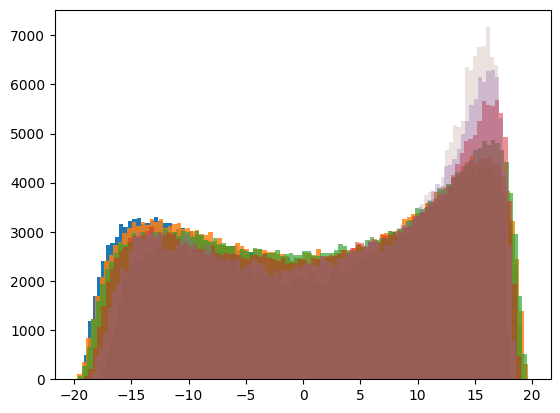

In [ ]:
close = in_sample.get_close_prices_series()

def calculate_smoothed_forecast(lookback):
    rolling_min = close.rolling(lookback).min().bfill()
    rolling_max = close.rolling(lookback).max().bfill()
    rolling_mean = (rolling_min + rolling_max) / 2

    raw_forecast = 40 * (close - rolling_mean) / (rolling_max - rolling_min)
    smoothed_forecast = raw_forecast.ewm(span=lookback * 2, adjust=False).mean()

    return smoothed_forecast

raw_forecast_10 = calculate_smoothed_forecast(10)  # last hour
raw_forecast_20 = calculate_smoothed_forecast(20)  # last 2 hours
raw_forecast_40 = calculate_smoothed_forecast(40)  # last 4 hours
raw_forecast_80 = calculate_smoothed_forecast(80)  # last 8 hours
raw_forecast_160 = calculate_smoothed_forecast(160)  # last 16 hours
raw_forecast_320 = calculate_smoothed_forecast(320)  # last 32 hours

print(f'raw_forecast_10_scalar = {10 / raw_forecast_10.abs().mean()}')
print(f'raw_forecast_20_scalar = {10 / raw_forecast_20.abs().mean()}')
print(f'raw_forecast_40_scalar = {10 / raw_forecast_40.abs().mean()}')
print(f'raw_forecast_80_scalar = {10 / raw_forecast_80.abs().mean()}')
print(f'raw_forecast_160_scalar = {10 / raw_forecast_160.abs().mean()}')
print(f'raw_forecast_320_scalar = {10 / raw_forecast_320.abs().mean()}')

raw_forecast_10_scalar = 0.9568254920786747
raw_forecast_20_scalar = 0.9863306513313047
raw_forecast_40_scalar = 0.9875011456362146
raw_forecast_80_scalar = 0.9635627949478376
raw_forecast_160_scalar = 0.9470841695331216
raw_forecast_320_scalar = 0.9216319480644363


scaled_forecast_10 = raw_forecast_10 * raw_forecast_10_scalar
scaled_forecast_20 = raw_forecast_20 * raw_forecast_20_scalar
scaled_forecast_40 = raw_forecast_40 * raw_forecast_40_scalar
scaled_forecast_80 = raw_forecast_80 * raw_forecast_80_scalar
scaled_forecast_160 = raw_forecast_160 * raw_forecast_160_scalar
scaled_forecast_320 = raw_forecast_320 * raw_forecast_320_scalar

combined_weighted_forecast = (
    scaled_forecast_10 * 1/6 +
    scaled_forecast_20 * 1/6 +
    scaled_forecast_40 * 1/6 +
    scaled_forecast_80 * 1/6 +
    scaled_forecast_160 * 1/6 +
    scaled_forecast_320 * 1/6
)

plt.hist(scaled_forecast_10, bins=100, alpha=6/6)
plt.hist(scaled_forecast_20, bins=100, alpha=5/6)
plt.hist(scaled_forecast_40, bins=100, alpha=4/6)
plt.hist(scaled_forecast_80, bins=100, alpha=3/6)
plt.hist(scaled_forecast_160, bins=100, alpha=2/6)
plt.hist(scaled_forecast_320, bins=100, alpha=1/6)
scaled_forecast_10.describe()


        Backtest Results from 2010-06-06 21:00:00-04:00 to 2023-09-29 17:00:00-04:00 (4862 days 20:00:00)
        Equity:     $100,000.00 -> $113,968.50
        Buy & Hold: $100,000.00 -> $820,129.42
        Buy & Hold Return (%): 720.13%
        Strategy Return (%):   13.97%

        Total Trades:     3625.00
        Win Rate:         30.10%
        95% CI:           28.63% - 31.61%
        Avg. Win:         $143.84
        Avg. Loss:        $-56.91
        Ratio Win/Loss:   2.53
        Expected Value:   $3.51

        Largest Win:      $3,264.50
        Largest Loss:     $-1,190.50
        Max Consec. Wins: 17
        Max Consec. Loss: 17

        Max Drawdown from 2022-09-01 13:00:00-04:00 to 2022-12-14 15:00:00-05:00 (104 days 03:00:00)
        Max Drawdown:     $-6,162.50
        Max Drawdown (%): -5.28%

        Slippage:   0 ticks
        Commission: $0.00
        Contract Multiplier: $2.00
        Transaction Costs:   $0.00

        CAGR:              0.99%
        Sharpe Rat

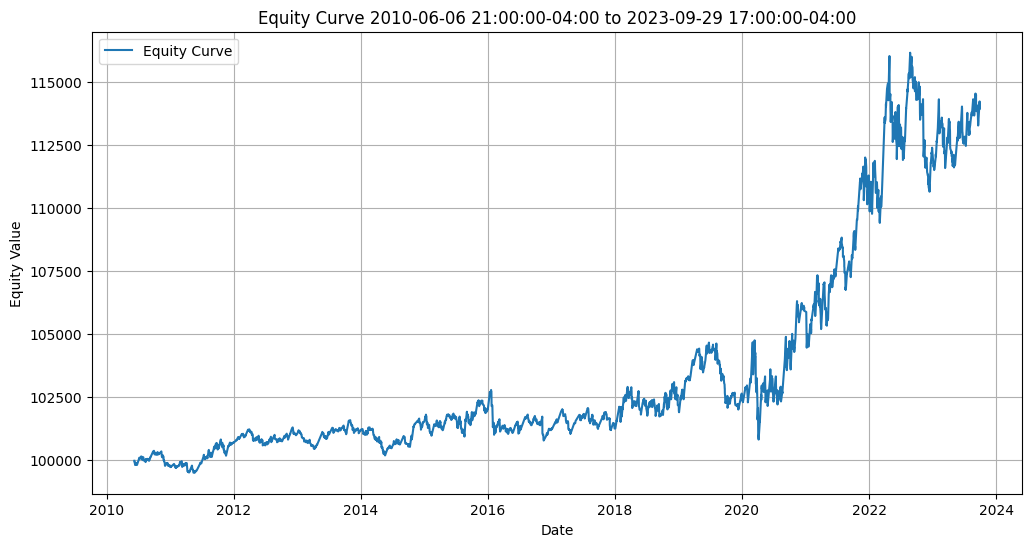

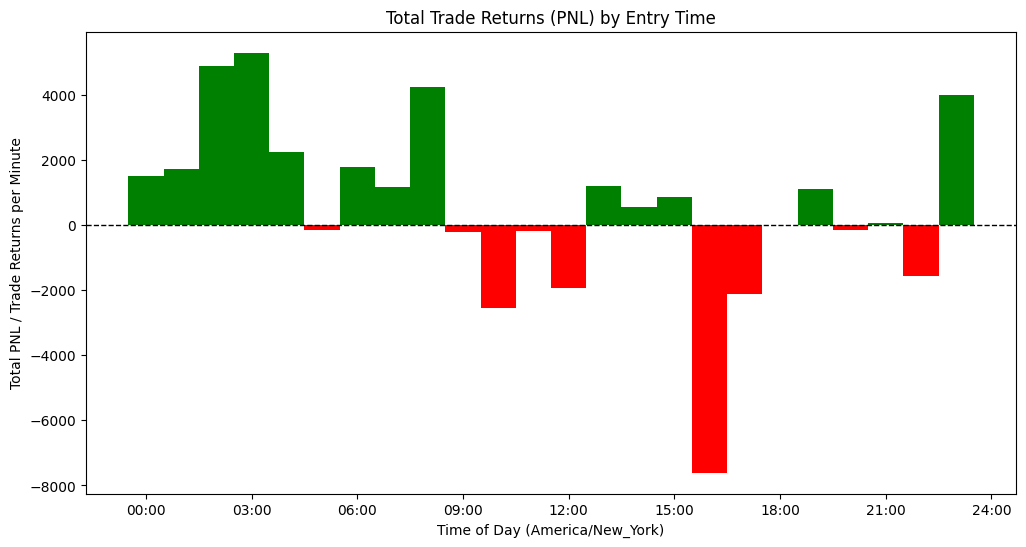

In [81]:
signal = np.where(combined_weighted_forecast > 0, 1, -1)

bt = Backtester(
    in_sample.get_ohlc_prices(),
    in_sample.get_indicies(),
    signal,
    timeframe=in_sample.get_timeframe(),
    tick_value=0.5,
    contract_multiplier=2,
    initial_equity=100_000,
    slippage_ticks=0,
    commission=0
)

bt.full_backtest()
print(bt)
bt.generate_equity_curve().plot()
bt.generate_trade_time_distribution()
